# Class 2 - Neural networks, and classifying enzymes

**AI in Quantitative Biology (Univ. Milano, 2026) - class 2 of 3, 90 min**
*Goes with `neural_networks_enzymes_slides.pptx` in this folder; slide numbers are the ones of that deck.*

Two parts:

| Part | Topic |
|---|---|
| A | A small neural network on the fish toxicity data of class 1 (regression) |
| B | Can we tell an enzyme's class from its amino-acid sequence? (classification) |

Part B introduces a trap that is everywhere in biological machine learning: **related sequences
leaking between training and test set**.


✏️ marks exercises and ❓ questions to discuss with your neighbour: try them yourself first, the solution follows right after.

## Setup

Everything runs on a laptop CPU in a few minutes; no GPU needed. The data are in the `data/`
folder of the course repository. The cell below finds it in the folders above
the notebook.

In [ ]:
# @title Setup: imports, data loading and helpers (run me)
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RNG = 0                                         # fixed seed: everyone gets the same numbers
pd.set_option("display.precision", 3)

import os
from pathlib import Path

def find_data_dir():
    """$QBIO_DATA if set, else the `data/` folder of the course repository (here or above)."""
    if os.environ.get("QBIO_DATA"):
        return Path(os.environ["QBIO_DATA"])
    here = Path.cwd().resolve()
    for p in [here, *here.parents]:
        if (p / "data" / "qsar_fish_toxicity.csv").exists():
            return p / "data"
    raise FileNotFoundError("Cannot find data/: run the notebook inside the course repository, "
                            "or set QBIO_DATA to the path of its data/ folder")

DATA_DIR = find_data_dir()
print("data from", DATA_DIR)

FISH_COLUMNS = ["CIC0", "SM1_Dz", "GATS1i", "NdsCH", "NdssC", "MLOGP", "LC50"]

def load_fish():
    """Fathead minnow 96 h LC50 for 908 chemicals (UCI QSAR fish toxicity)."""
    return pd.read_csv(DATA_DIR / "qsar_fish_toxicity.csv", sep=";", header=None, names=FISH_COLUMNS)

def load_enzymes():
    """2047 Swiss-Prot enzymes labelled by top-level EC class."""
    return pd.read_csv(DATA_DIR / "enzymes.tsv", sep="\t")

AA = "ACDEFGHIKLMNPQRSTVWY"                     # the 20 standard amino acids

def aa_composition(seq):
    """Fraction of each of the 20 amino acids in `seq` (a vector of length 20)."""
    return np.array([seq.count(a) for a in AA]) / len(seq)

def plot_confusion(y_true, y_pred, labels, title=None):
    """Confusion matrix as a heatmap: rows = true class, normalised per row."""
    from sklearn.metrics import confusion_matrix
    cm = confusion_matrix(y_true, y_pred, labels=labels, normalize="true")
    ax = plt.subplots(figsize=(len(labels) + 2, len(labels) + 1))[1]
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    for i in range(len(labels)):
        for j in range(len(labels)):
            ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center",
                    color="white" if cm[i, j] > 0.5 else "black", fontsize=9)
    ax.set_xticks(range(len(labels)), labels, rotation=45, ha="right")
    ax.set_yticks(range(len(labels)), labels)
    ax.set_xlabel("predicted"); ax.set_ylabel("true")
    if title:
        ax.set_title(title)

data from /Users/toni/Sync/teaching/c-courses/2026 AI QBio/classes/data


# Can we tell an enzyme's class from its sequence?

Enzymes are classified by the reaction they catalyse into **EC (Enzyme Commission) classes**:

| EC | class | reaction |
|---|---|---|
| 1 | Oxidoreductases | transfer of electrons (redox) |
| 2 | Transferases | transfer of a group (methyl, phosphate, ...) |
| 3 | Hydrolases | cleavage by water |
| 4 | Lyases | cleavage without water or oxidation |
| 5 | Isomerases | rearrangement within a molecule |
| 6 | Ligases | joining two molecules, using ATP |

Our dataset contains **2047 enzymes** from UniProt/Swiss-Prot (manually reviewed), from five model
organisms (human, *E. coli*, baker's yeast, *Arabidopsis*, *B. subtilis*), about 350 per class.
Each enzyme also has its **protein family** (groups of evolutionarily related proteins).

## B1 - Meet the data

In [ ]:
enz = load_enzymes()
print(enz.shape)
enz.head()

(2047, 10)


,accession,entry_name,protein_name,organism,ec,ec_class,ec_name,family,length,sequence
0,A8MRX0,GSOX5_ARATH,Flavin-containing monooxygenase FMO GS-OX5,Arabidopsis thaliana,1.14.13.237,1,Oxidoreductase,FMO family,459,MAPARTRVNSLNVAVIGAGAAGLVAARELRRENHTVVVFERDSKVG...
1,A9X4U2,HSDD3_ARATH,3beta-hydroxysteroid-dehydrogenase/decarboxyla...,Arabidopsis thaliana,1.1.1.170,1,Oxidoreductase,3-beta-HSD family,561,MDEDSVHGDSHLKTCVVLGGRGFIGRSLVSRLLRLGNWTVRVADSG...
2,F4ILF8,P4H13_ARATH,Prolyl 4-hydroxylase 13,Arabidopsis thaliana,1.14.11.2,1,Oxidoreductase,P4HA family,274,MRSYGKEKKLVFPYVFIACCFFLAIFGFCFFNLFSQGISFSEIPTT...
3,F4K2M8,JMJ31_ARATH,Lysine-specific demethylase JMJ31,Arabidopsis thaliana,1.14.11.-,1,Oxidoreductase,JARID1 histone demethylase family,549,MPTGCEFPMIKTFENALTAADFESTVELTNFPAVFRGCASVWDAYS...
4,F4KAV2,AKB1D_ARATH,DNA N,Arabidopsis thaliana,1.14.11.51,1,Oxidoreductase,AlkB family,442,MLNSIHRSFHLTSRHQIVLRLCSPSASRTIMSSSPHSPIPKTHTAS...


In [ ]:
print(enz["ec_name"].value_counts(), "\n")
pd.crosstab(enz["organism"], enz["ec_name"])

ec_name
Oxidoreductase    350
Transferase       350
Hydrolase         350
Lyase             350
Isomerase         350
Ligase            297
Name: count, dtype: int64 



ec_name,Hydrolase,Isomerase,Ligase,Lyase,Oxidoreductase,Transferase
organism,,,,,,
Arabidopsis thaliana,121,100,67,118,128,149
Bacillus subtilis,37,55,63,63,53,32
Escherichia coli,32,73,64,65,49,39
Homo sapiens,120,72,58,57,88,98
Saccharomyces cerevisiae,40,50,45,47,32,32


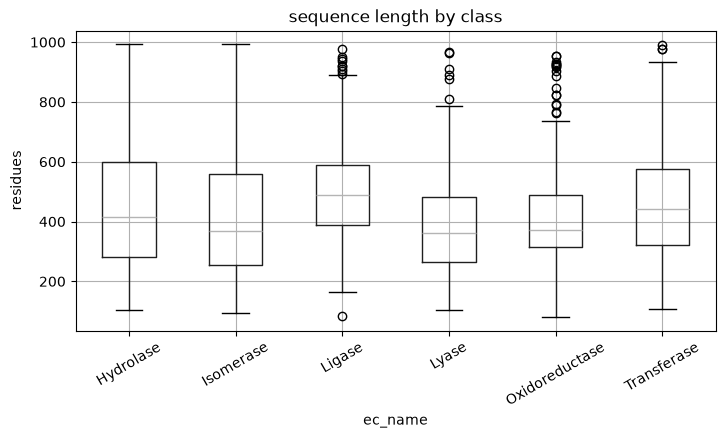

In [ ]:
classes = sorted(enz["ec_name"].unique())
enz.boxplot(column="length", by="ec_name", figsize=(8, 4), rot=30)
plt.suptitle(""); plt.title("sequence length by class"); plt.ylabel("residues");

✏️ **Exercise B1.1.** Print one example sequence and its protein name. How many proteins come from
the largest protein family, and what is that family? *Hint:* `value_counts()` on `family`.

In [ ]:
row = enz.iloc[0]
print(row["protein_name"], "|", row["organism"], "| EC", row["ec"])
print(row["sequence"])
print()
print(enz["family"].value_counts().head(5))

Flavin-containing monooxygenase FMO GS-OX5 | Arabidopsis thaliana | EC 1.14.13.237
MAPARTRVNSLNVAVIGAGAAGLVAARELRRENHTVVVFERDSKVGGLWVYTPNSEPDPLSLDPNRTIVHSSVYDSLRTNLPRECMGYRDFPFVPRPEDDESRDSRRYPSHREVLAYLEDFAREFKLVEMVRFKTEVVLVEPEDKKWRVQSKNSDGISKDEIFDAVVVCNGHYTEPRVAHVPGIDSWPGKQIHSHNYRVPDQFKDQVVVVIGNFASGADISRDITGVAKEVHIASRSNPSKTYSKLPGSNNLWLHSMIESVHEDGTIVFQNGKVVQADTIVHCTGYKYHFPFLNTNGYITVEDNCVGPLYEHVFPPALAPGLSFIGLPWMTLQFFMFELQSKWVAAALSGRVTLPSEEKMMEDVTAYYAKREAFGQPKRYTHRLGGGQVDYLNWIAEQIGAPPGEQWRYQEINGGYYRLATQSDTFRDKWDDDHLIVEAYEDFLRQKLISSLPSQLLES

family
FMO family                                                             8
NAD(P)-dependent epimerase/dehydratase family                          8
Peroxidase family, Classical plant (class III) peroxidase subfamily    8
Zinc-containing alcohol dehydrogenase family                           8
Aldehyde dehydrogenase family                                          8
Name: count, dtype: int64


## B2 - Amino-acid composition

The simplest way to turn a sequence of any length into a fixed-size vector: the **fraction of
each of the 20 amino acids**. This forgets the order completely.

In [ ]:
comp = pd.DataFrame(np.vstack(enz["sequence"].map(aa_composition)), columns=list(AA))
comp.head()

,A,C,D,E,F,G,H,I,K,L,M,N,P,Q,R,S,T,V,W,Y
0,0.063,0.009,0.063,0.070,0.044,0.065,0.033,0.044,0.044,0.072,0.017,0.041,0.061,0.035,0.065,0.072,0.044,0.096,0.020,0.044
1,0.062,0.016,0.059,0.043,0.078,0.066,0.023,0.053,0.053,0.109,0.014,0.030,0.027,0.025,0.050,0.103,0.048,0.087,0.016,0.036
2,0.055,0.022,0.051,0.066,0.084,0.066,0.026,0.051,0.062,0.077,0.015,0.044,0.047,0.040,0.047,0.077,0.058,0.051,0.011,0.051
3,0.077,0.016,0.062,0.077,0.049,0.044,0.038,0.044,0.049,0.111,0.029,0.044,0.044,0.031,0.046,0.106,0.038,0.055,0.015,0.027
4,0.034,0.016,0.054,0.061,0.041,0.063,0.032,0.063,0.057,0.084,0.020,0.048,0.059,0.036,0.075,0.124,0.059,0.052,0.007,0.016


Is any amino acid enriched in a class? We compare each class's mean composition with the overall
mean, on a $\log_2$ scale (+1 = twice as frequent).

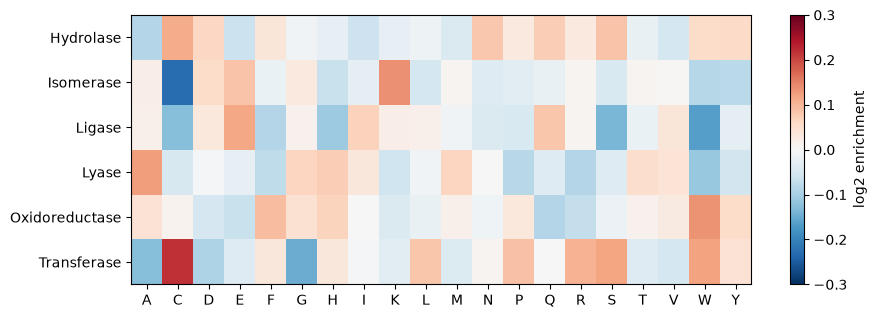

In [ ]:
class_mean = comp.groupby(enz["ec_name"]).mean()
enrichment = np.log2(class_mean / comp.mean())

plt.figure(figsize=(10, 3.5))
plt.imshow(enrichment, cmap="RdBu_r", vmin=-0.3, vmax=0.3, aspect="auto")
plt.colorbar(label="log2 enrichment")
plt.xticks(range(20), AA); plt.yticks(range(len(classes)), enrichment.index);

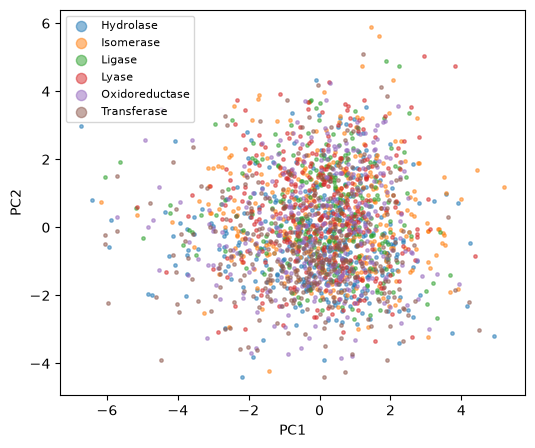

In [ ]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

Z = PCA(n_components=2).fit_transform(StandardScaler().fit_transform(comp))
plt.figure(figsize=(6, 5))
for c in classes:
    sel = (enz["ec_name"] == c).values
    plt.scatter(Z[sel, 0], Z[sel, 1], s=6, alpha=0.5, label=c)
plt.legend(markerscale=3, fontsize=8); plt.xlabel("PC1"); plt.ylabel("PC2");

❓ How large are the differences in composition between classes? Do the classes separate in the
PCA map? What do you expect for a classifier?

**Answer.** The enrichments are tiny (within ±0.25 on a log2 scale, i.e. < 20%) and the classes
overlap completely in the PCA map. Composition carries only a faint signal about the catalysed
reaction: expect a classifier to do better than chance, but not much. (Some enrichments have a
story: Cys is enriched among transferases because ~15% of them transfer ubiquitin (EC 2.3.2.x,
e.g. RING-type E3 ligases), whose zinc-binding domains contain twice the average Cys.)

## B3 - Classifiers

Features: the 20 composition values plus log(length). We measure **accuracy** (fraction of
correct predictions) with stratified 5-fold cross-validation (each fold keeps the class
proportions). With 6 balanced classes, **random guessing gives about 1/6 = 0.17**.

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score


Xe = comp.assign(log_length=np.log(enz["length"]))
ye = enz["ec_name"]
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RNG)

classifiers = {
    "logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "random forest": RandomForestClassifier(n_estimators=300, random_state=RNG, n_jobs=-1),
    "MLP (64)": make_pipeline(StandardScaler(),
                              MLPClassifier(hidden_layer_sizes=(64,), alpha=1e-3, early_stopping=True,
                                            max_iter=500, random_state=RNG)),
}
acc_random = {}
for name, clf in classifiers.items():
    acc_random[name] = cross_val_score(clf, Xe, ye, cv=skf, scoring="accuracy").mean()
    print(f"{name:20s} accuracy = {acc_random[name]:.3f}")

logistic regression  accuracy = 0.291


Accuracy hides *which* classes get confused. A **confusion matrix** shows, for each true class (row),
how the predictions are distributed (columns). `cross_val_predict` gives one out-of-fold prediction
per enzyme.

In [ ]:
pred_rf = cross_val_predict(classifiers["random forest"], Xe, ye, cv=skf)
plot_confusion(ye, pred_rf, classes, title="random forest, random 5-fold CV");

❓ Which class is easiest to recognise, which is hardest? Any idea why?

**Answer.** Look at the diagonal: no class is easy (recall ≈ 0.30-0.45 each) and the errors
spread over all columns. Oxidoreductases are the hardest: a huge and chemically diverse class
(NAD-, FAD-, heme-, metal-dependent enzymes in many unrelated folds) with no common composition.
EC classes describe the *chemistry* of the reaction, which evolution has invented many times in
unrelated folds, so composition is a weak proxy for it.

## B4 - The homology trap

Proteins of the same **family** share a common ancestor and often have similar sequences - and
similar compositions. With a random split, a test enzyme usually has a close relative
(e.g. the same enzyme from another organism) in the training set, and the model can just
"recognise the family" instead of learning anything general.

A fairer test for a *new* kind of enzyme: keep **whole families** out of the training set.
`StratifiedGroupKFold` does this - all members of a group end up in the same fold.

In [ ]:
from sklearn.model_selection import StratifiedGroupKFold

print(enz["family"].nunique(), "families;", (enz["family"].value_counts() > 1).sum(), "with more than one member")
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RNG)
groups = enz["family"]

✏️ **Exercise B4.1.** Repeat the cross-validation of the three classifiers with `cv=sgkf` and
`groups=groups` (pass it as `cross_val_score(..., groups=groups)`), and print both accuracies
side by side.

In [ ]:
for name, clf in classifiers.items():
    acc_family = cross_val_score(clf, Xe, ye, cv=sgkf, groups=groups, scoring="accuracy").mean()
    print(f"{name:20s} random split = {acc_random[name]:.3f}   family split = {acc_family:.3f}")

❓ Which model loses the most when families are held out, and why? Which number would you report
in a paper claiming "our model predicts the class of newly discovered enzymes"?

**Answer.** The random forest drops the most (≈ 0.40 → 0.30): it is the most flexible model and
partly works as a "find the relative" lookup table. Logistic regression and the MLP drop less
because they were learning less family-specific detail in the first place. For new enzymes, the
family-split number is the honest one. The random-split number answers a different question
("can I annotate a new member of a family I already know?") - for which a BLAST search against
annotated sequences would beat all of these models.

Where exactly does the inflated random-split accuracy come from? For each enzyme, count how many
members of its family were in the **training folds** when it was predicted (in the random 5-fold CV
of B3), and compare the accuracy of the random forest across these groups.

In [ ]:
# @title Support code: accuracy vs number of relatives in training (figure)
fold = np.zeros(len(enz), dtype=int)
for i, (_, test_idx) in enumerate(skf.split(Xe, ye)):
    fold[test_idx] = i
fam = enz["family"].fillna("").values
n_relatives = np.array([0 if fam[j] == "" else ((fam == fam[j]) & (fold != fold[j])).sum()
                        for j in range(len(enz))])
correct = (pred_rf == ye.values)

bins = pd.cut(n_relatives, [-1, 0, 1, 3, 100], labels=["0", "1", "2-3", "4+"])
by_rel = pd.DataFrame({"relatives in training": bins, "correct": correct}) \
           .groupby("relatives in training", observed=True)["correct"].agg(["mean", "size"])
print(by_rel)

ax = by_rel["mean"].plot.bar(rot=0, color="tab:blue", figsize=(6, 4), label="accuracy")
for i, (acc, n) in enumerate(zip(by_rel["mean"], by_rel["size"])):
    ax.text(i, acc + 0.01, f"n = {n}", ha="center", fontsize=8)
ax.axhline(1 / 6, color="grey", ls=":", label="chance")
ax.axhline(acc_random["random forest"], color="k", ls="--", label="overall (random split)")
ax.set_ylabel("random forest accuracy"); ax.set_xlabel("family members in the training folds")
ax.legend(fontsize=8);

❓ What does this plot say about the random-split accuracy?

**Answer.** Accuracy grows with the number of relatives in the training set. Enzymes with no relative
in training get ≈ 0.33, close to the family-split number (≈ 0.31), while those with 4 or more
relatives get ≈ 0.55: the random forest is largely recognising the family.
The random-split accuracy is an average over these groups, so it depends on how many relatives the
dataset happens to contain, not only on how good the model is.

## Summary

* An MLP is a flexible function approximator; on a small table it overfits easily, needs scaled
  inputs and regularisation, and does not beat a random forest.
* **Data mining before modelling** told us what to expect: the enzyme classes barely differ in
  composition, and models got 0.25-0.40 accuracy (chance: 0.17).
* **How you split matters as much as which model you use.** Related sequences across the
  train/test boundary inflate the scores; split by family (or by sequence identity) to estimate
  performance on genuinely new proteins.
* Composition throws away the **order** of the residues. Next class: a neural network that reads
  the sequence residue by residue.

### If you have time

✏️ Replace composition by **dipeptide** frequencies (400 features: AA, AC, ..., YY) and redo the
random vs family comparison for the random forest. Does the gap grow or shrink?

In [ ]:
import itertools
DIPEPTIDES = ["".join(p) for p in itertools.product(AA, repeat=2)]
index = {dp: i for i, dp in enumerate(DIPEPTIDES)}

def dipeptide_composition(seq):
    v = np.zeros(len(DIPEPTIDES))
    for i in range(len(seq) - 1):
        v[index[seq[i:i + 2]]] += 1
    return v / (len(seq) - 1)

Xd = np.vstack(enz["sequence"].map(dipeptide_composition))
rf = classifiers["random forest"]
print(f"random split: {cross_val_score(rf, Xd, ye, cv=skf).mean():.3f}")
print(f"family split: {cross_val_score(rf, Xd, ye, cv=sgkf, groups=groups).mean():.3f}")

**Answer.** Dipeptides do not help (≈ 0.38 random, ≈ 0.28 family split, vs 0.40 / 0.31 with
composition): 400 noisy features for 2047 proteins is a lot, and the leakage gap stays ≈ 0.09.
More features is not the same as more information.

## References and data sources

**Data**

* `qsar_fish_toxicity.csv`: 908 compounds, 96-h LC50 for the fathead minnow (*Pimephales promelas*) with six molecular descriptors (UCI Machine Learning Repository, "QSAR fish toxicity"; Cassotti et al. 2015).
* Enzyme and targeting tables: reviewed entries of UniProtKB/Swiss-Prot (UniProt Consortium 2023), downloaded with the UniProt REST API on 2026-11-10 from human, *E. coli* K-12, yeast, *Arabidopsis* and *B. subtilis*; Swiss-Prot changes at every release, so the committed TSVs are the reference. See `course/README.md` and `data_prep/`.

**Further reading**

* Kapoor S, Narayanan A (2023). Leakage and the reproducibility crisis in machine-learning-based science. *Patterns* 4:100804. [doi:10.1016/j.patter.2023.100804](https://doi.org/10.1016/j.patter.2023.100804) — the vocabulary for the leakage in Part B
* Yu T, Cui H, Li JC, et al. (2023). Enzyme function prediction using contrastive learning. *Science* 379:1358–1363. [doi:10.1126/science.adf2465](https://doi.org/10.1126/science.adf2465) — CLEAN, a recent EC-number predictor: composition alone genuinely cannot do this task
* Lin Z, Akin H, Rao R, et al. (2023). Evolutionary-scale prediction of atomic-level protein structure with a language model. *Science* 379:1123–1130. [doi:10.1126/science.ade2574](https://doi.org/10.1126/science.ade2574) — the protein language model used in extra03